# Camera Pose Calibration From LEDs

**Status: steps 1-3 done below (LED centroid extraction verified against all three
rings; real LED glint detection tuned against one real frame; predicted pixel
positions from the assumed pose, via rendering rather than analytical projection).
Steps 4-5 -- matching detected/predicted pixels and solving for the recovered pose
-- are not yet implemented.**

Goal: recover each camera's real-world pose from the real chamber's LED ring lights
(`led_ring_1/2/3`), independent of LAr10Ana's bubble triangulation and the older 5-point
fiducial pentagon `PnP_Test_Chamber.ipynb` uses. A same-day investigation (2026-09-16)
first suspected the S-curve of bright dots visible in every real image was the SiPM array
(`sipm_covers`/`sipm_detectors`) -- ruled out by removing those components from a render
and seeing no change to the dot pattern -- before confirming it's `led_ring_1/2/3`
(removing `led_ring_1` made exactly one of the three dot-loops vanish). LEDs make a better
calibration target than either alternative: CAD-exact 3D position per LED, high-contrast
against a dark background, and 57 points per ring (vs. 40 SiPMs or 5-9 fiducials).

## Plan

1. **Extract LED 3D centroids** from `led_ring_1/2/3`'s mesh -- done
   (`led_calibration.load_led_centroids`).
2. **Detect real LED glints** in a chosen `camN-imgNN.png` frame -- done
   (`led_calibration.detect_led_glints`), tuned against one real frame only so far.
3. **Predict pixel positions** for the assumed pose -- done
   (`led_calibration.predict_led_pixels`), but *not* by projecting the known centroids
   directly (a straight-line pinhole projection doesn't work here -- checked: what's
   visible of the LEDs in a real photo is a *reflection* off the curved dome, not a
   direct view). Renders the assumed pose instead and detects glints in the render
   itself, the same way this repo's own render() was used to originally identify these
   LEDs as the dot pattern's source.
4. Nearest-neighbor match detected <-> predicted pixels -- not started.
5. Solve for the recovered pose via `estimate_pose_matrix()` (already in `utils.py`, wraps
   `cv2.solvePnP`) and compare to the assumed pose -- not started.

In [1]:
import os, sys
if not os.path.isdir("modules"):
    os.chdir("..")
sys.path.insert(0, "modules")

from utils import *
import led_calibration as lc

## Step 1: LED centroids

In [2]:
# One (57, 3) array of cm-space centroids per ring, plus which ring each row came from
# (for coloring the plot below and, later, for tagging matches by which camera's own ring
# they belong to).
centroidsByRing = {ringName: lc.load_led_centroids(ringName) for ringName in lc.LED_RING_NAMES}

for ringName, centroids in centroidsByRing.items():
    print(f"{ringName}: {centroids.shape[0]} LEDs")

led_ring_1: 57 LEDs
led_ring_2: 57 LEDs
led_ring_3: 57 LEDs


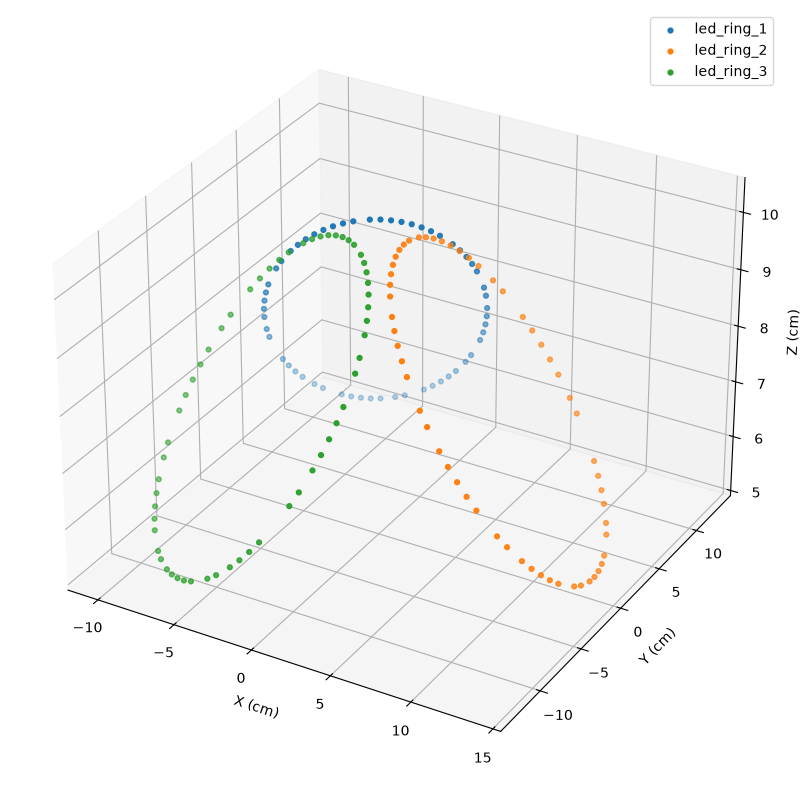

In [3]:
# Sanity-check the extracted centroids visually -- each ring should form one clean loop
# in 3D, not a scattered/noisy cloud, before trusting them as PnP input later.
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(projection='3d')
ax.set_xlabel("X (cm)")
ax.set_ylabel("Y (cm)")
ax.set_zlabel("Z (cm)")

for ringName, centroids in centroidsByRing.items():
    ax.scatter(centroids[:, 0], centroids[:, 1], centroids[:, 2], s=12.0, label=ringName)

ax.legend()
fig.tight_layout()

## Step 2: Detect real LED glints

In [4]:
import real_data_loading as rdl

# Same run/event/camera/frame as RealDataRenderComparison.ipynb, for consistency.
runName = "20251114_37"
runDir = rdl.RUN_DIRS[runName]
camera = 1
frame = 16

realImage = load_image(rdl.camera_image_path(runDir, 1, camera, frame))
glintPixels = lc.detect_led_glints(realImage)

print(f"{glintPixels.shape[0]} candidate glints detected in cam{camera} frame{frame}")

199 candidate glints detected in cam1 frame16


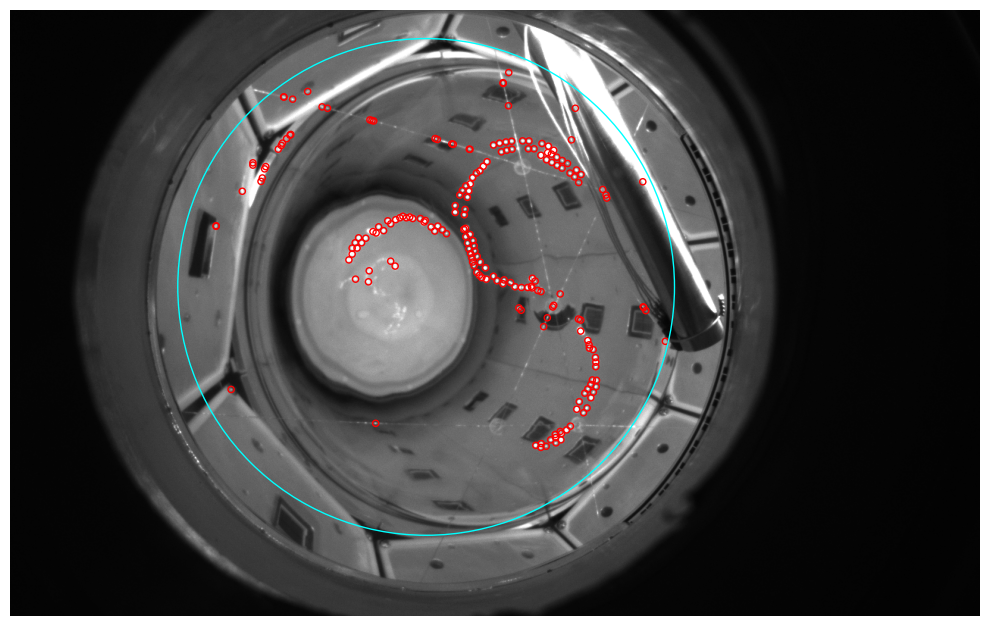

In [5]:
# Sanity check: overlay the detected glints on the real image, plus the fitted
# interior/rim boundary (detect_led_glints already used it to drop the rim's own
# specular highlights, but drawing it here shows why the remaining detections were
# kept -- they all land on the dot pattern, well inside that boundary). detect_led_glints
# compares each pixel to its own local surroundings rather than one global brightness
# cutoff, which is what recovers the fainter LEDs reflected onto the illuminated disc --
# an equally-real glint there is much dimmer in absolute terms than one on the dark wall.
# A few real false positives (a shiny tool poking into the interior, a couple of wall
# panel-seam corners) are still expected (see detect_led_glints' docstring) and will get
# filtered out naturally once step 4 only keeps detections near a *predicted* LED.
viewportCenter, viewportRadius = lc.detect_viewport_circle(realImage)
maxRadiusFraction = 0.70  # keep in sync with detect_led_glints()'s default

fig, ax = plt.subplots(figsize=(10, 6.4))
ax.imshow(realImage, cmap='gray')
ax.scatter(glintPixels[:, 0], glintPixels[:, 1], s=20, facecolors='none', edgecolors='red')
ax.add_patch(plt.Circle(viewportCenter, viewportRadius * maxRadiusFraction, fill=False, color='cyan'))
ax.axis('off')
fig.tight_layout()

## Step 3: Predict pixel positions from the assumed pose

In [6]:
# Renders cam{camera}'s assumed pose (no bubble) at full quality and detects glints in
# the render itself -- see predict_led_pixels()'s docstring for why a direct pinhole
# projection of the known 3D centroids doesn't work (the LEDs are only visible via
# reflection off the curved dome) and why it needs a much higher contrastThreshold than
# a real photo (render grain, unlike sensor noise, doesn't survive a light denoise
# without also washing out the glints -- easier to just raise the bar past it).
# Takes ~5 minutes on this CPU-only machine, same as any other full-quality render here.
predictedPixels = lc.predict_led_pixels(camera)

print(f"{predictedPixels.shape[0]} predicted glints for cam{camera}'s assumed pose")

2026-09-17 11:13:05 WARN  [PLYMesh] "outer_jar_outer_surface_top_distorted.ply": skipping unknown element "edge"
2026-09-17 11:13:05 WARN  [PLYMesh] "outer_jar_inner_surface_top_distorted.ply": skipping unknown element "edge"
2026-09-17 11:13:05 WARN  [PLYMesh] "inner_jar_outer_surface_bottom.ply": skipping unknown element "edge"


107 predicted glints for cam1's assumed pose


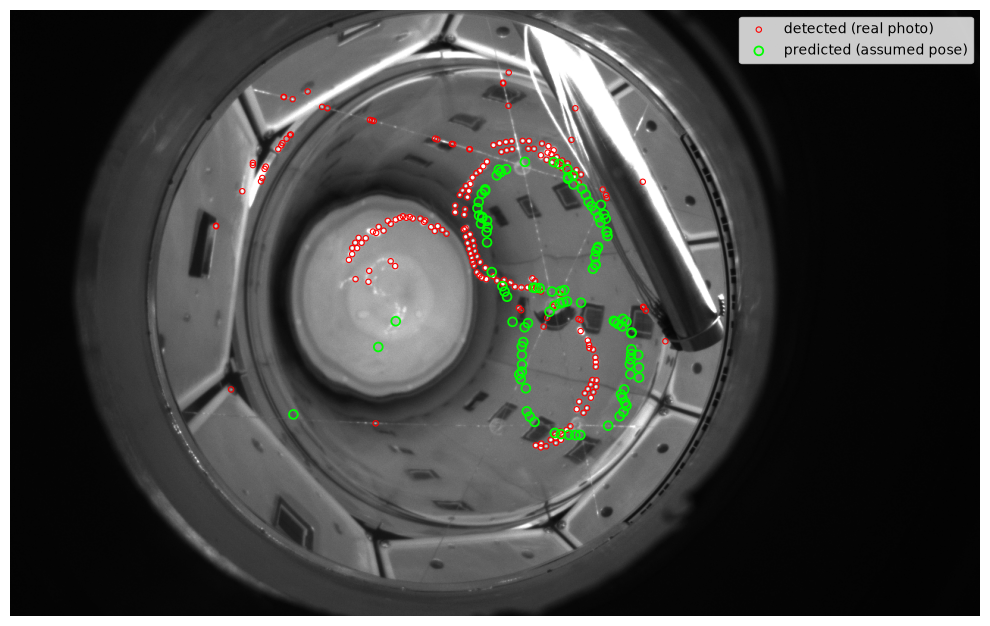

In [7]:
# Sanity check: overlay the real detected glints (step 2) against the render-predicted
# ones (step 3) on the real photo. If the assumed pose exactly matched the physical
# camera, these would coincide (up to detection noise); how far apart they are is
# itself a first, rough look at the pose error this whole branch exists to measure --
# though the real photo also has fisheye lens distortion the render's ideal pinhole
# camera model doesn't, so not all of the gap is pose error. The disc-reflected arc's
# predictions are sparse (see predict_led_pixels()'s docstring on render noise there),
# so don't expect a match in that region specifically.
fig, ax = plt.subplots(figsize=(10, 6.4))
ax.imshow(realImage, cmap='gray')
ax.scatter(glintPixels[:, 0], glintPixels[:, 1], s=15, facecolors='none', edgecolors='red',
           linewidths=0.8, label='detected (real photo)')
ax.scatter(predictedPixels[:, 0], predictedPixels[:, 1], s=40, facecolors='none', edgecolors='lime',
           linewidths=1.3, label='predicted (assumed pose)')
ax.legend()
ax.axis('off')
fig.tight_layout()

## Steps 4-5 (not yet implemented)

Next up is step 4 -- nearest-neighbor matching the detected and predicted pixels
(with a max-distance cutoff), which is also where the remaining false positives
from both step 2 (shiny tool, panel-seam corners) and step 3 (render noise) are
expected to fall away, before step 5 solves for the recovered pose via
`estimate_pose_matrix()`.